# Chiu & Roy Validation — Wall-PPP NTN RT Stochastic Simulation

**Companion to `stochastic_simulation.ipynb`.** Same pipeline, different
*generative geometry*: instead of the block-PPP urban scenes used for the
3GPP TR 38.811 cross-check, every realisation is a Poisson point process of
**oriented wall slabs** — the spatial process $\Phi$ of eq. (4) in

> K.-P. Chiu and S. Roy, *Joint Delay–Doppler Modeling of Multipath LEO
> Channels* (UW; submitted to IEEE T-AES).

The purpose is to test that paper's **analytical** model against a full ray
tracer on the *identical* scene process. Every number in the paper comes from
its own closed forms plus a scene Monte Carlo of the same geometric
assumptions; nothing there tests whether the electromagnetics behind them
(single-bounce Fresnel reflection, UTD roof-edge diffraction, and the two
visibility approximations) survive contact with real ray tracing.

Reference implementation and the authors' published figure data are cloned at
`/path/to/chiu_roy_ref`.

## The scene process

$N \sim \mathrm{Poisson}(\lambda_b \pi R_{\rm city}^2)$ wall centres uniform in a
disc about the terminal; each wall a rectangle of length $\ell_f$, orientation
$\xi \sim \mathcal{U}[0,\pi)$, standing on the ground with an **untruncated**
Rayleigh($\gamma$) height (eq. 5). No exclusion zone about the terminal — a wall
may stand a few metres away, which is what blocks LoS at high elevation.

| | $\gamma$ | $\lambda_b$ | $\ell_f$ | $\lambda_{1D} = 2\lambda_b\ell_f/\pi$ |
|---|---|---|---|---|
| urban | 8 m | $1.96\times10^{-3}$ m$^{-2}$ | 20 m | 0.025 /m |
| rural | 3 m | $3.14\times10^{-3}$ m$^{-2}$ | 10 m | 0.020 /m |

Terminal at $(0,0,1.5\,\mathrm{m})$ — the PPP's own reference point, **not** a
free-space sample. 550 km circular orbit, $f_c$ = 2 GHz, omnidirectional
terminal, single-bounce (`MAX_DEPTH = 1`), specular + UTD only (no diffuse).

## Geometry gate: the scene generator is verified against the closed form

Before any GPU time, `validate_chiu_roy.py gate` ray-tests our own ensemble
against the paper's LoS-probability closed form, eq. (56). At 4000 scenes per
point, **every elevation lands within $\pm1\sigma$** in both scenes:

| $\beta_{\rm ele}$ | 10° | 20° | 30° | 40° | 50° | 60° | 70° | 80° |
|---|---|---|---|---|---|---|---|---|
| urban MC | .297 | .549 | .691 | .780 | .837 | .886 | .926 | .962 |
| urban eq. (56) | .298 | .556 | .691 | .776 | .836 | .884 | .925 | .963 |
| rural MC | .770 | .877 | .921 | .946 | .965 | .976 | .984 | .992 |
| rural eq. (56) | .769 | .880 | .923 | .946 | .962 | .974 | .983 | .992 |

Our closed form also matches the authors' own `pg` to machine precision, and our
independent ray test matches their `Model.clear()` on 300/300 shared cities.

## Scene radius: the paper's 2 km

Statistics converge far below this — P_LoS by 250 m, non-direct power and RMS
delay spread by 250–500 m, both verified against the closed form and against the
authors' own implementation. Running at the paper's own 2 km simply removes the
question: eq. (56)'s truncation term is numerically zero there, so the analytic
reference is the published eq. (27) exactly as printed, with nothing to defend.

It costs ~24,700 walls per urban scene, which is affordable only because the
sweep is **scene-outer** (below).

## Scene-outer sweep

Scenes are not pre-built. At 2 km a scene is ~9 MB, so a 2,000-scene ensemble on
disk would be ~18 GB that then gets re-parsed once per elevation and
polarization — sixteen times over. Instead `run_chiu_sweep.py` generates scene
*k* from seed `PPP_BASE_SEED + k`, solves **every elevation and both
polarizations on it**, and deletes it:

| | pre-built ensemble | scene-outer (this notebook) |
|---|---|---|
| scene generated | once | once |
| scene parsed | 16× | **1×** |
| peak disk | ~18 GB | **~9 MB** |
| measured | — | 1.7 s gen + 0.15 s load + 16 × 0.75 s solve = **~14 s/scene** |

2,000 scenes across two GPUs is **under 4 h per scenario**. Workers take
contiguous scene chunks (equal work each, unlike an elevation split), and
`chiu_setup.merge_chunks()` reassembles them **in scene order** into the ordinary
`results_elev{NNN}deg.pkl` layout, so every downstream consumer is unchanged.

Seeds are deterministic, so an elevation sweep sees one identical scene: per-scene
statistics stay pairable across elevation, and V/H can be averaged per path — which
the polarization-averaged Fresnel kernel requires. The inner loop re-aims the same
loaded scene (`scene_utils.set_tx_pose` / `set_polarization`) rather than rebuilding
it, verified bit-exact against a fresh build at every elevation and both polarizations.

## Four ray-tracer defects this notebook works around

Found and measured while bringing the pipeline up; each would have silently
corrupted the comparison. Details in the `chiu_setup.py` module docstring.

1. **Material thickness.** Sionna reflects off a *slab* of finite `thickness`
   (default 0.1 m), so reflections carry thin-film interference with the back
   face instead of the semi-infinite Fresnel coefficient the paper uses —
   multi-dB, and non-monotonic in $\epsilon_r$. Fixed with `thickness` = 2 m
   **plus a small ground conductivity**: a *lossless* slab never converges at
   any thickness. Section 5 asserts the half-space match (now within 0.01 dB).
2. **float32 delays.** `paths.tau` is float32; one ULP at 550 km is ~0.47 ns,
   against delay spreads of 3.7 ns. `run_chiu_sweep.py` therefore re-derives every
   excess delay in float64 from `paths.vertices` (metre-scale, so float32 there is
   millimetre-accurate). That reproduces the paper's ground taps exactly
   (3.42 ns at 20°, 9.85 ns at 80°) where `tau` gives 3.26 / 9.78, and it is
   reproducible to ~1 fs run to run. The delay spread is computed on those
   float64 values, not on `tau`.
3. **Polarization.** The paper's kernel is the polarization *average*
   $\tfrac12(|\Gamma_{\rm TE}|^2+|\Gamma_{\rm TM}|^2)$. A circularly polarized
   wave is invariant under rotation about its propagation axis, so it splits
   exactly 50/50 into the **local** TE and TM modes at every interaction,
   whatever that interaction's plane of incidence. RHCP transmit into a
   **complete dual-port receive**, port powers summed, therefore reproduces the
   kernel identically — measured at **0.00 dB** against the reference model's own
   per-path amplitudes on wall reflections at arbitrary orientation — and in one
   solve instead of two.

   Both receive components must be summed; a single-sense CP measurement is not
   the average (co-polar RHCP→RHCP collapses to −46 dB at 80° on the ground,
   because reflection flips handedness).

   The earlier approach — averaging two co-polar linear runs,
   $\tfrac12(P_{VV}+P_{HH})$ — is exact only where the plane of incidence aligns
   with the V/H basis. That holds for the **ground** (vertical plane of
   incidence), which is why ground checks passed at 0.01 dB, but not for a
   randomly oriented wall, where it discards the cross-polar V→H conversion:

   | ψ (plane of incidence vs V/H basis) | 0° | 15° | 30° | 45° | 60° | 75° | 90° |
   |---|---|---|---|---|---|---|---|
   | `0.5(P_VV+P_HH)` error | 0.00 | −1.04 | −4.40 | **−8.23** | −4.40 | −1.04 | 0.00 dB |
   | CP total error | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 dB |

   Over ten reference wall reflections the co-polar average came in a mean of
   1.50 dB low (worst 6.24 dB). It is kept as
   `POLARIZATION_MODE = "linear_copol_avg"` for cross-checking.

4. **Ground-path dropouts.** Sionna's specular refinement intermittently fails
   to return the ground path (~6% of geometries): exact when found,
   unrecoverable by more sampling, and *systematic per elevation*. Since the
   ground bounce carries 69–92% of the non-direct power, `GROUND_RETRY_MAX`
   re-solves with a small RX jitter and reports what it could not recover.

## What differs from `stochastic_simulation.ipynb`

- `scene_gen_ppp.generate_scene_ensemble(primitive="wall", ...)` instead of the
  block-PPP sampler
- one UE per scene **pinned at the origin** (`PPP_RX_AT_ORIGIN`), not sampled
  from free space
- `SCENARIO` switch (`"urban"` / `"rural"`) — re-run the notebook for the other
- scene-outer streaming sweep rather than a pre-built ensemble (Section 6)
- one RHCP/dual-port solve per elevation, reproducing the paper's
  polarization-averaged kernel exactly (`POLARIZATION_MODE`)
- parameters are imported from `chiu_setup.py` rather than retyped, so this
  notebook and the CLI path cannot drift

Otherwise identical: same config/ensemble/multi-GPU-launch/checkpoint
machinery, same section numbering.


## 1 - Environment Setup

In [1]:
import os, sys

# DrJIT / LLVM path
# NOTE: previously followed by `%env DRJIT_LIBLLVM_PATH="..."` -- removed.
# IPython's %env magic does not strip quotes from the value, so that line
# was setting os.environ['DRJIT_LIBLLVM_PATH'] to the literal string
# '"/usr/lib/x86_64-linux-gnu/libLLVM-20.so"' (quote characters included).
# Harmless for drjit in this kernel (already initialized on the line above,
# using the correct unquoted value) but fatal for any subprocess launched
# later (Section 6) that inherits this corrupted value via env=os.environ
# and tries to load DrJIT/LLVM fresh.
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

# Add script directory to path so helper modules can be imported
SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)


print("Environment configured.")

Environment configured.


## 2 - Imports

In [2]:
import json
import pickle
import shutil
import subprocess
import time
import numpy as np
from scipy import constants
%matplotlib inline
import matplotlib.pyplot as plt

# Sionna / DrJIT / Mitsuba are imported for their backend setup, not by name.
import sionna
import sionna.rt
from sionna.rt import load_scene   # Section 5 material check
import drjit
import mitsuba as mi

# Local helpers
from channel_utils    import elevation_summary
from checkpoint_utils import load_results, simulation_status
from plot_utils       import plot_cdfs

from atmospheric_utils import atmospheric_deterministic_summary
from ionospheric_utils import ionospheric_summary
from fetch_vtec        import vtec_for_pipeline
from fetch_tle         import fetch_tle_catalog

from orbital_utils import (
        slant_range_m,
        make_reference_satrec, find_pass,
        find_pass_with_geometry_class, REFERENCE_LEO_ALTITUDES_KM,
        generate_waypoints, parse_tle_catalog, parse_tle_text,
        search_tle_catalog_for_pass, best_pass_in_catalog,
    )
from sgp4.api import jday

import scene_gen_ppp as sg

print("All imports OK.")

# Chiu & Roy validation: parameters and the analytic reference live here, so the
# notebook and the CLI driver (chiu_setup.py) cannot drift apart.
import chiu_setup as cs
import validate_chiu_roy as v

print("Chiu validation helpers OK.")


All imports OK.
Chiu validation helpers OK.


## 3 - Global Parameters

> **Update the values in this cell before running.**  
> Every simulation knob is exposed here.

In [3]:
# ─── SCENE (wall PPP ensemble -- Chiu & Roy eq. 4; see Section 5) ─────────────
# Re-run this notebook with SCENARIO = "rural" for the other environment; every
# path below is scenario-scoped so the two never collide.
SCENARIO        = "rural"          # "urban" | "rural"
SCENE_CENTER    = [0.0, 0.0]       # every wall scene is centred on the origin

_SC             = sg.WALL_SCENARIOS[SCENARIO]
PPP_GAMMA       = _SC["gamma"]     # Rayleigh wall-height scale [m]
PPP_LAM_B       = _SC["lam_b"]     # wall-centre density [walls/m^2]
PPP_L_F         = _SC["l_f"]       # wall length [m]
PPP_LAMBDA_1D   = 2 * PPP_LAM_B * PPP_L_F / np.pi   # line-crossing intensity [1/m]

# The paper's own R_city. Statistics are converged far below this (P_LoS by
# 250 m, non-direct power and RMS DS by 250-500 m), but at 2 km there is simply
# nothing to defend: eq. (56)'s truncation term is numerically zero, so the
# analytic reference is the published eq. (27) exactly as printed. Affordable
# because the sweep is scene-outer -- one scene is generated, solved at every
# elevation and polarization, and discarded (see Section 6).
R_CITY          = cs.R_CITY        # [m] scene disc radius (2 km)
WALL_THICK      = cs.WALL_THICK    # [m] slab thickness -- see below
SCENE_RADIUS    = R_CITY           # sizes the TX beam footprint in Sec. 3.6

# Walls are thin SLABS, not zero-thickness plates: the paper's UTD coefficient
# assumes a right-angle roof wedge (n = 3/2, a vertical face meeting a
# horizontal roof). A zero-thickness plate is a half-plane, n = 2, which would
# bias every diffracted amplitude.
PPP_H_MIN       = 0.0              # paper's Rayleigh (eq. 5) is UNtruncated
PPP_H_MAX       = np.inf

# ── Scene location & simulation date ────────────────────────────────────────
# Recorded for reproducibility; the overhead-pass sweep in Sec. 3.6 does not
# use them, but the Doppler follow-up (synthetic_orbit mode) will.
SIM_LAT             =  47.6553     # UW campus
SIM_LON             = -122.3035
SIM_DATE            = "2026-06-15"


# ─── RF ───────────────────────────────────────────────────────────────────────
FREQUENCY       = cs.FREQUENCY     # 2 GHz, the paper's carrier
TX_POWER_DBM    = 43.0
RX_HEIGHT       = cs.H_G           # 1.5 m terminal (paper's h_g)

# ─── MATERIALS ────────────────────────────────────────────────────────────────
# Walls: ITU-R P.2040 concrete, exactly as the paper. Ground: eps_r = 3.5.
#
# The `thickness` key is the important one. Sionna models a material as a SLAB
# and reflects off both faces, so at the 0.1 m default a reflection carries
# thin-film interference rather than the semi-infinite half-space Fresnel
# coefficient the paper's kernel uses -- a multi-dB error that is NOT monotonic
# in permittivity. thickness >= ~1 m on a LOSSY material recovers the half-space
# value; a lossless slab never converges at any thickness, which is why the
# ground carries sigma = 0.05 S/m (which itself moves |Gamma|^2 by < 0.15 dB).
# Section 5 asserts this.
PPP_WALL_PARAMS   = dict(cs.WALL_PARAMS)      # P.2040 concrete + thickness
PPP_ROOF_PARAMS   = dict(cs.WALL_PARAMS)      # roof cap is the same concrete
PPP_GROUND_PARAMS = dict(cs.GROUND_PARAMS)    # eps_r 3.5, sigma 0.05, 2 m

SCATTERING_COEFF = 0.0             # no diffuse scattering: the paper omits it
ETA_R            = PPP_WALL_PARAMS["a"] * (FREQUENCY / 1e9) ** PPP_WALL_PARAMS["b"]
SIGMA            = PPP_WALL_PARAMS["c"] * (FREQUENCY / 1e9) ** PPP_WALL_PARAMS["d"]

PPP_BUILDING_MATERIAL = cs.WALL_MAT      # dummy ITU identity strings; the real
PPP_ROOF_MATERIAL     = cs.ROOF_MAT      # EM parameters are the dicts above,
PPP_GROUND_MATERIAL   = cs.GROUND_MAT    # applied by build_scene_batch()
MATERIAL_NAMES        = sorted({PPP_BUILDING_MATERIAL, PPP_ROOF_MATERIAL,
                                PPP_GROUND_MATERIAL})

# ─── PROPAGATION FLAGS ────────────────────────────────────────────────────────
# Single-bounce, specular + UTD diffraction only -- exactly the paper's
# mechanism set (one wall reflection, one ground bounce, one edge diffraction).
# Depth 3 would add multipath the analytics never claims to model.
MAX_DEPTH           = 1
LOS                 = True
SPECULAR_REFLECTION = True
DIFFUSE_REFLECTION  = False    # the paper omits diffuse and vegetation scatter
DIFFRACTION         = True
EDGE_DIFFRACTION    = False
REFRACTION          = False

# ─── BEAMFORMING ──────────────────────────────────────────────────────────────
# This is a ray-LAUNCH cone, not an antenna taper: path power ratios are
# invariant from 1x to 100x the scene half-angle (measured). It is required
# because an isotropic source at 550 km puts essentially no rays on the scene.
# The terminal antenna stays omnidirectional, as the paper specifies.
BEAMFORMING  = True

# ─── SAMPLING ─────────────────────────────────────────────────────────────────
BASE_SAMPLES_PER_SRC = 10_000_000
BASE_MAX_PATHS       = 10_000_000

# ─── WALL PPP SCENE ENSEMBLE ──────────────────────────────────────────────────
# One realisation = one independent random wall scene. Fixed parameters, seed
# sweep: only the seed varies across N_SCENES realisations, so the statistics
# come from scene randomness alone. The same ensemble is reused, unchanged,
# across every elevation angle AND both polarizations.
# Scenes are NOT pre-built. At 2 km a scene is ~24,700 walls / ~9 MB, so a
# 2000-scene ensemble on disk would be ~18 GB that then gets re-parsed once per
# elevation and polarization -- sixteen times over. Section 6 streams instead:
# generate scene k from seed PPP_BASE_SEED+k, solve all 16 (elevation,
# polarization) combinations on it, delete it. Seeds are deterministic, so an
# elevation sweep still sees one identical scene and per-scene statistics stay
# pairable across elevation.
N_SCENES                 = 2000
PPP_BASE_SEED            = 0
N_WORKERS                = 2        # parallel scene chunks, one GPU each
CHUNK_DIR                = f"./chiu_validation/chunks_{SCENARIO}_r{int(R_CITY)}"
SWEEP_CONFIG_FILE        = f"./chiu_validation/sweep_config_{SCENARIO}.json"

# ─── RECEIVER ─────────────────────────────────────────────────────────────────
# ONE UE per scene, pinned at (0, 0, RX_HEIGHT). This is the paper's model
# exactly: the terminal is the PPP's own reference point and the scene is
# redrawn about it per realisation (Slivnyak). Note this is the OPPOSITE of the
# block-PPP notebook, which samples UEs from free space -- that is the right
# choice there, because a block scene's origin gate guarantees the centre is
# outdoors and would inflate LoS. Walls carry no footprint area and the
# reference model has no exclusion zone, so neither concern applies.
N_RX_PER_SCENE           = 1
PPP_RX_AT_ORIGIN         = True

# ─── GPU ──────────────────────────────────────────────────────────────────────
NUM_GPUS = 2   # Set to 1 to disable multi-GPU parallelism

# ─── CHECKPOINTING ────────────────────────────────────────────────────────────
RNG_SEED            = 42
CHECKPOINT_INTERVAL = 20
RAW_SAVE_INTERVAL   = 1      # every scene: the PDP and Doppler analysis need
                             # per-path data from ALL of them, not a sample
SAVE_PATH_VERTICES  = True   # float64 excess delays + ground/wall path split
RESULTS_ROOT        = "./chiu_validation"
RESUME_FROM_CHECKPOINT = True

# ─── GROUND-PATH DROPOUT RETRY ────────────────────────────────────────────────
# Sionna intermittently fails to return the ground-reflected path (~6% of
# geometries). It is exact where returned and unrecoverable by extra sampling,
# but flips with a sub-millimetre RX move -- and it is systematic per elevation,
# so an affected angle would lose it in EVERY scene. The ground bounce carries
# 69-92% of the non-direct power here, so losing it silently would bias K.
GROUND_RETRY_MAX      = 4
GROUND_RETRY_JITTER_M = 0.05

# ─── POLARIZATION ─────────────────────────────────────────────────────────────
# The paper's Fresnel kernel is the polarization AVERAGE,
# 0.5*(|G_TE|^2 + |G_TM|^2), and likewise 0.5*(|D_TE|^2 + |D_TM|^2) for the UTD
# roof-edge coefficient.
#
# "cp_total" realises that exactly, in ONE solve. A circularly polarized wave is
# invariant under rotation about its propagation axis, so it splits exactly
# 50/50 into the LOCAL TE and TM modes at every interaction, whatever that
# interaction's plane of incidence. Transmitting RHCP into a COMPLETE dual-port
# ("VH") receive and summing the two port powers therefore reproduces the kernel
# identically -- measured at 0.00 dB against the reference model's own per-path
# amplitudes, on wall reflections at arbitrary orientation.
#
# Both receive components must be summed. A single-sense CP measurement is NOT
# the average: co-polar RHCP->RHCP collapses to -46 dB at 80 deg on the
# eps_r = 3.5 ground, because reflection flips handedness.
#
# "linear_copol_avg" is the earlier approach -- two co-polar runs, V->V and
# H->H, powers averaged. It is exact only where the plane of incidence aligns
# with the V/H basis. That holds for the GROUND (vertical plane of incidence,
# verified 0.00 dB) but not for a randomly oriented wall, where it discards the
# cross-polar V->H conversion and under-counts specular wall reflection by a
# measured mean of 1.50 dB, worst 6.24 dB. Kept for cross-checking.
POLARIZATION_MODE = "cp_total"          # or "linear_copol_avg"
POLARIZATIONS     = cs.POL_LABELS[POLARIZATION_MODE]   # result-file labels
POL_BASE_PATTERN  = "iso"
ELEVATION_ANGLES_HINT = 8   # set for real in Sec. 3.6; used only by the print below

# ─── DERIVED ──────────────────────────────────────────────────────────────────
LAMBDA_C     = constants.c / FREQUENCY
PERTURB_HALF = LAMBDA_C

print(f"Scenario             : {SCENARIO}")
print(f"  gamma={PPP_GAMMA:g} m  lambda_b={PPP_LAM_B:.4e} /m^2  "
      f"l_f={PPP_L_F:g} m  lambda_1D={PPP_LAMBDA_1D:.4f} /m")
print(f"  R_city={R_CITY:g} m  -> E[walls/scene] = {PPP_LAM_B*np.pi*R_CITY**2:.0f}")
print(f"\nCarrier frequency    : {FREQUENCY/1e9:.2f} GHz   (wavelength {LAMBDA_C*100:.2f} cm)")
print(f"Terminal             : h_g={RX_HEIGHT} m at the origin, omnidirectional")
print(f"Walls   eta_r={ETA_R:.2f}  sigma={SIGMA:.4f} S/m  thickness={PPP_WALL_PARAMS['thickness']} m")
print(f"Ground  eps_r={PPP_GROUND_PARAMS['a']:.2f}  sigma={PPP_GROUND_PARAMS['c']:.3f} S/m  "
      f"thickness={PPP_GROUND_PARAMS['thickness']} m")
print(f"\nPropagation: LoS={LOS}  Spec={SPECULAR_REFLECTION}  "
      f"DiffRefl={DIFFUSE_REFLECTION}  Diffr={DIFFRACTION}  "
      f"Refr={REFRACTION}  max_depth={MAX_DEPTH}")
print(f"Polarization         : {POLARIZATION_MODE} -> labels {POLARIZATIONS}")
print(f"\nScene ensemble       : N_SCENES={N_SCENES}, 1 UE/scene at the origin "
      f"(streamed, not pre-built)")
print(f"Inner loop           : {N_SCENES} scenes x {ELEVATION_ANGLES_HINT} "
      f"elevations x {len(POLARIZATIONS)} pol")
print(f"Chunks dir           : {CHUNK_DIR}")
print(f"Results root         : {RESULTS_ROOT}")


Scenario             : rural
  gamma=3 m  lambda_b=3.1416e-03 /m^2  l_f=10 m  lambda_1D=0.0200 /m
  R_city=2000 m  -> E[walls/scene] = 39478

Carrier frequency    : 2.00 GHz   (wavelength 14.99 cm)
Terminal             : h_g=1.5 m at the origin, omnidirectional
Walls   eta_r=5.24  sigma=0.0795 S/m  thickness=2.0 m
Ground  eps_r=3.50  sigma=0.050 S/m  thickness=2.0 m

Propagation: LoS=True  Spec=True  DiffRefl=False  Diffr=True  Refr=False  max_depth=1
Polarization         : cp_total -> labels ['cp']

Scene ensemble       : N_SCENES=2000, 1 UE/scene at the origin (streamed, not pre-built)
Inner loop           : 2000 scenes x 8 elevations x 1 pol
Chunks dir           : ./chiu_validation/chunks_rural_r2000
Results root         : ./chiu_validation


## 3.5 - Atmosphere & Ionosphere Modeling

Scene location/date, ionospheric model (Faraday rotation + group delay/phase advance) and its VTEC source (manual or live IGS GIM auto-fetch, run inline below), and the atmospheric model (gaseous absorption, rain attenuation, tropospheric scintillation). Toggle each model on/off here.

**CDDIS auth (one-time setup, only if `VTEC_AUTO_FETCH=True`):**
```
# ~/.netrc
machine urs.earthdata.nasa.gov login <user> password <pass>
```
Register free at https://urs.earthdata.nasa.gov/  
BKG FTP mirror is tried automatically as a no-auth fallback.

In [4]:
# NOTE: both models are DISABLED for the 3GPP cross-check. TR 38.811 carries\n# atmospheric / ionospheric / scintillation losses as SEPARATE link-budget\n# terms, so leaving them on here would bias sigma_SF against the reference.\n# ─── IONOSPHERIC MODEL (ITU-R P.531-15 + Faraday rotation) ───────────────────
# Master switch. Set True to enable Faraday pre-rotation (pre-RT) and
# ionospheric group delay + phase advance corrections (post-RT).
IONOSPHERE_ENABLED  = False

# ── VTEC auto-fetch ──────────────────────────────────────────────────────────
# Set True to pull live IGS GIM VTEC from NASA CDDIS / BKG mirror for the
# (SIM_LAT, SIM_LON, SIM_DATE) triple above. Set False to always use the
# manual fallback values below. The fetch (if requested) runs immediately
# below, in this same cell.
#
# CDDIS auth (one-time setup, only needed if VTEC_AUTO_FETCH=True):
#   ~/.netrc:  machine urs.earthdata.nasa.gov login <user> password <pass>
#   Register free at https://urs.earthdata.nasa.gov/
#   BKG FTP mirror is tried automatically as a no-auth fallback.
VTEC_AUTO_FETCH     = False
IONEX_CACHE_DIR     = "./ionex_cache"   # local directory for cached IONEX files
VTEC_CV_FLOOR       = 0.30             # minimum CV: VTEC_STD >= CV_FLOOR * VTEC_MEAN

# Earthdata auth for the VTEC fetch below: export EARTHDATA_TOKEN, or add
# urs.earthdata.nasa.gov to ~/.netrc. fetch_vtec.py checks the env var first.
os.environ.setdefault("EARTHDATA_TOKEN", "")

# ── Manual / fallback VTEC parameters ────────────────────────────────────────
# Active when VTEC_AUTO_FETCH = False, or if the fetch below fails.
# See ionospheric_utils.TEC_PRESETS for reference values:
#   quiet_night_midlat (3 ± 1.5 TECU)  |  quiet_day_midlat  (10 ± 5 TECU)
#   active_day_midlat  (30 ± 15 TECU)  |  storm_midlat      (60 ± 30 TECU)
VTEC_MEAN_TECU      = 10.0    # mean vertical TEC [TECU]
VTEC_STD_TECU       =  5.0    # std dev of vertical TEC [TECU]
B_L_TESLA           =  2e-5   # mean longitudinal B-field along path [T]
VTEC_SIGMA_H        =  0.0    # elevation-dependent extra TEC scatter (0 = constant CV)

if IONOSPHERE_ENABLED and VTEC_AUTO_FETCH:
    print(f"[VTEC] Fetching IGS GIM for "
          f"({SIM_LAT:.2f}° N, {SIM_LON:.2f}° E) on {SIM_DATE} ...")
    try:
        _vtec = vtec_for_pipeline(
            lat       = SIM_LAT,
            lon       = SIM_LON,
            date      = SIM_DATE,
            cache_dir = IONEX_CACHE_DIR,
            cv_floor  = VTEC_CV_FLOOR,
        )
        VTEC_MEAN_TECU = _vtec["VTEC_MEAN_TECU"]
        VTEC_STD_TECU  = _vtec["VTEC_STD_TECU"]
        print(f"[VTEC] ✓  VTEC_MEAN_TECU overridden -> {VTEC_MEAN_TECU} TECU")
        print(f"[VTEC] ✓  VTEC_STD_TECU  overridden -> {VTEC_STD_TECU} TECU")
    except Exception as _vtec_err:
        print("[VTEC] WARNING: fetch failed — keeping manual fallback values.")
        print(f"       Reason : {_vtec_err}")
        print(f"[VTEC] VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU  (manual)")
        print(f"[VTEC] VTEC_STD_TECU  = {VTEC_STD_TECU} TECU  (manual)")
elif IONOSPHERE_ENABLED:
    print("[VTEC] Auto-fetch disabled — using manual values:")
    print(f"       VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU")
    print(f"       VTEC_STD_TECU  = {VTEC_STD_TECU} TECU")
else:
    print("[VTEC] Ionosphere disabled — skipping VTEC fetch.")

# ─── ATMOSPHERIC MODEL (ITU-R P.676-12 + P.838-3 + P.618-13) ─────────────────
# Master switch. Set True to enable gaseous absorption, rain attenuation,
# and tropospheric scintillation.
ATMOSPHERE_ENABLED  = False

# Surface conditions — drive gaseous absorption (P.676) and scintillation (P.618).
# See atmospheric_utils.WEATHER_PRESETS for named scenarios:
#   cold_dry | temperate_moderate | warm_humid | tropical | high_altitude
ATM_T_K             = 288.15    # surface temperature [K]
ATM_P_HPA           = 1013.25   # surface pressure [hPa]
ATM_RHO_G_M3        =    7.5    # fixed surface water-vapour density [g/m³]

# Rain model — drives rain attenuation (P.838-3 + P.618-13).
# Set RAIN_R_MM_H = 0.0 for a clear-sky (no-rain) scenario.
RAIN_R_MM_H         =    0.0    # fixed rain rate [mm/h]; 0 = clear sky

# Geometry / antenna
ATM_H_STATION_KM    =    0.0    # station height above MSL [km]
ATM_H_RAIN_KM       =    3.36   # mean rain height (0°C isotherm + 0.36 km) [km]
ATM_POL_TILT_DEG    =   45.0    # TX polarisation tilt from horizontal [deg]; 45° = circular
ATM_D_ANT_M         =    0.0    # receive antenna diameter [m]; 0 = point antenna (no aperture averaging)
ATM_SCINTILLATION   = True      # include tropospheric scintillation

# ── Model status ──────────────────────────────────────────────────────────────
# Elevation-dependent summaries (ionospheric_summary / atmospheric_deterministic_
# summary) print at the end of §3.6 instead of here, once ELEVATION_ANGLES is
# known from whichever satellite mode is selected there.
print()
if IONOSPHERE_ENABLED:
    _vtec_src = "live IGS GIM" if VTEC_AUTO_FETCH else "manual fallback"
    print(f"Ionospheric model : ENABLED   VTEC source = {_vtec_src}")
    print(f"                    VTEC_MEAN={VTEC_MEAN_TECU} TECU  "
          f"VTEC_STD={VTEC_STD_TECU} TECU  B_L={B_L_TESLA*1e6:.1f} µT")
else:
    print("Ionospheric model : DISABLED  (set IONOSPHERE_ENABLED=True above)")

if ATMOSPHERE_ENABLED:
    print(f"Atmospheric model : ENABLED   ρ={ATM_RHO_G_M3} g/m³  "
          f"R={RAIN_R_MM_H} mm/h  Scint={'ON' if ATM_SCINTILLATION else 'OFF'}")
else:
    print("Atmospheric model : DISABLED")


[VTEC] Ionosphere disabled — skipping VTEC fetch.

Ionospheric model : DISABLED  (set IONOSPHERE_ENABLED=True above)
Atmospheric model : DISABLED


## 3.6 - Satellite Sweep: Elevation Sweep, Synthetic Orbit, Real-Satellite Search, or Manual TLE

Four modes, toggled via `SATELLITE_SOURCE`:

- **`synthetic_sweep`** (legacy/default) — fixed `ELEVATION_ANGLES` + `SLANT_DIST_M`, no real orbit, no Doppler.
- **`synthetic_orbit`** — an *invented* circular LEO orbit (you pick altitude/inclination), SGP4-propagated to find when that fabricated orbit passes over the ground station (`SIM_LAT`/`SIM_LON`). No real satellite is involved.
- **`real_search`** — searches a bulk catalog of *real* satellites' published TLEs (e.g. all active Starlink, downloaded from celestrak) and finds whichever real one(s) actually have a pass over the ground station. `PASS_GEOMETRY` here filters real results by real max elevation; it does not invent anything.
- **`manual_tle`** — pins one *specific* real satellite by pasting its own published TLE into `MANUAL_TLE_TEXT`, instead of searching a whole catalog. Use this when you want a named, reproducible satellite (e.g. a particular Starlink launch, or the ISS) rather than whichever one happens to qualify.

All search/propagation logic lives in `orbital_utils.py` (`find_pass`, `find_pass_with_geometry_class`, `search_tle_catalog_for_pass`) — this cell only selects options and reports results.

In [5]:
# ─── SATELLITE SWEEP ──────────────────────────────────────────────────────────
# SATELLITE_SOURCE selects the mode:
#   "synthetic_sweep" (legacy/default) -- fixed ELEVATION_ANGLES + SLANT_DIST_M
#                       + TX_AZIMUTH_DEG, no real orbit, no Doppler.
#   "synthetic_orbit" -- an INVENTED 3GPP TR 38.821 circular LEO (you choose
#                       altitude/inclination), SGP4-propagated to find when
#                       fabricated orbit produces a pass over the ground
#                       station. No real satellite is involved.
#   "real_search"     -- searches a bulk catalog of REAL satellites' published
#                       TLEs (e.g. all active Starlink) and finds whichever
#                       real one(s) actually pass over the ground station.
#                       Nothing about the orbit is invented here; every
#                       candidate is a real tracked object.
#   "manual_tle"      -- pins ONE specific REAL satellite by its own published
#                       TLE (pasted into MANUAL_TLE_TEXT below) instead of
#                       searching a whole catalog. Use this for a named,
#                       reproducible satellite rather than "whichever one
#                       happens to qualify".
# Ground station location for all three orbit modes comes directly from
# SIM_LAT / SIM_LON (set in Section 3.5) -- no separate lat/lon input here.
SATELLITE_SOURCE = "synthetic_sweep"   # "synthetic_sweep" | "synthetic_orbit" | "real_search" | "manual_tle"

# --- default fallback (SATELLITE_SOURCE == "synthetic_sweep") ---
# SWEEP_ALTITUDE_KM makes run_stochastic_sim.py derive the TRUE
# spherical-Earth slant range per elevation (orbital_utils.slant_range_m)
# instead of using one fixed distance -- the paper's 550 km circular orbit.
SWEEP_ALTITUDE_KM = cs.H_SAT_KM     # [km] 550 km LEO
SLANT_DIST_M     = float(slant_range_m(SWEEP_ALTITUDE_KM, 40.0))  # mid-pass fallback
TX_AZIMUTH_DEG   = cs.TX_AZIMUTH  # 181 deg. The scene is isotropic (xi is
                                  # uniform), so azimuth is statistically
                                  # irrelevant -- but an EXACTLY axis-aligned
                                  # azimuth is a degenerate geometry for
                                  # Sionna's specular refinement, so don't sit on one.
ELEVATION_ANGLES = [10, 20, 30, 40, 50, 60, 70, 80, 90]  # Elevation angles to simulate [deg]
# 90 deg is dropped: at zenith a vertical ray cannot reflect off an offset
# vertical wall toward the terminal, so wall reflection vanishes by
# construction, and the paper plots 10-80 deg for the same reason.

# --- only used when SATELLITE_SOURCE == "real_search" ---
# Bulk 3-line-format TLE text file covering many real satellites, e.g. fetched
# from https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=TLE
# (repeating [name, line1, line2] blocks -- no blank-line separators needed).
TLE_CATALOG_FILE   = None          # e.g. "./tle_catalog/starlink.tle"
TLE_AUTO_FETCH      = True         # True -> auto-download TLE_GROUP via fetch_tle.py if TLE_CATALOG_FILE is None
TLE_GROUP           = "starlink"   # celestrak GROUP name -- see https://celestrak.org/NORAD/elements/
TLE_CACHE_DIR       = "./tle_catalog"
TLE_MAX_AGE_HOURS   = 6.0          # re-fetch if the cached catalog is older than this (LEO TLEs go stale within hours)
MAX_SATELLITES_SCAN = None         # cap how many catalog entries to propagate
                                   # (None = scan the whole catalog; bulk
                                   # catalogs can have thousands of entries)
CATALOG_SELECT     = "highest_elev"     # "soonest" | "highest_elev" -- how to pick
                                   # one real satellite among all qualifying ones.
                                   # Ignored when PASS_GEOMETRY="overhead": that mode
                                   # always picks the pass closest to true zenith
                                   # (highest max elevation), regardless of this setting.

# --- only used when SATELLITE_SOURCE == "manual_tle" ---
# Paste ONE real satellite's own published TLE here -- 2 or 3 lines (optional
# name line + the two numbered element lines), exactly as published, e.g.
# copied straight out of a bulk catalog file or from
# https://celestrak.org/NORAD/elements/gp.php?CATALOG_NUMBER=<norad_id>&FORMAT=TLE
# Unlike real_search, this locks in one specific object instead of searching
# a whole catalog for whichever satellite happens to pass.
MANUAL_TLE_TEXT = None
# Example:
# MANUAL_TLE_TEXT = """
# ISS (ZARYA)
# 1 25544U 98067A   24001.50000000  .00016717  00000-0  10270-3 0  9994
# 2 25544  51.6416 339.9863 0007286  92.8340  40.2027 15.49309620427776
# """

# --- used when SATELLITE_SOURCE in ("synthetic_orbit", "real_search", "manual_tle") ---
GS_ALT_KM           = 0.0         # ground station altitude [km]
                                  # (lat/lon come from SIM_LAT/SIM_LON, Section 3.5)
ORBIT_REFERENCE     = "leo600"    # "leo600" | "leo1200"   (synthetic_orbit only)
ORBIT_INCLINATION   = 53.0        # deg                     (synthetic_orbit only)
ORBIT_RAAN_DEG      = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any")
ORBIT_ARG_LAT_DEG   = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any");
                                  # sweep this if PASS_SEARCH_HOURS finds no pass at "any"
PASS_MIN_ELEV_DEG   = 10.0
PASS_ELEV_STEP_DEG  = 10.0
PASS_LEG            = "rising"    # "rising" | "setting"
PASS_SEARCH_HOURS   = 24.0
PASS_EPOCH          = "2026-07-28T00:00:00"        # ISO8601 UTC; None -> 2026-01-01 default in both modes

# --- Pass geometry class ---
# "any" | "overhead" | "near" | "far"
# synthetic_orbit mode: searches invented RAAN/arg_lat for a fabricated orbit
#   matching this class -- see orbital_utils.find_pass_with_geometry_class.
# real_search mode: FILTERS real satellites' real passes to this class
#   instead of inventing anything -- see orbital_utils.search_tle_catalog_for_pass.
# manual_tle mode: not used (there's only one candidate satellite -- whatever
#   pass it has is the pass you get).
PASS_GEOMETRY              = "overhead" # "any" | "overhead" | "near" | "far"
PASS_GEOMETRY_RAAN_GRID    = 8       # synthetic_orbit only
PASS_GEOMETRY_ARG_LAT_GRID = 8       # synthetic_orbit only

# --- Doppler (only meaningful when SATELLITE_SOURCE != "synthetic_sweep") ---
DOPPLER_ENABLED        = True
DOPPLER_WINDOW_S       = 0.01
DOPPLER_SAMPLING_HZ    = 1e4
DOPPLER_NUM_TIME_STEPS   = 128    # time samples for the Doppler-modulated CIR cross-check
DOPPLER_OVERSAMPLE_FACTOR = 10.0  # sampling_frequency = this * (fc/c)*|TX_VEL| -- see run_elevation_sim.py
SCENE_EAST_HEADING_DEG = 90.0      # compass heading of the scene's +X axis

WAYPOINTS_FILE = None   # populated below if SATELLITE_SOURCE != "synthetic_sweep"


def _parse_iso_epoch(s):
    year, rest = s.split("-", 1); month, rest = rest.split("-", 1)
    day, rest  = rest.split("T", 1); hour, minute, sec = rest.split(":")
    return int(year), int(month), int(day), int(hour), int(minute), float(sec)


if SATELLITE_SOURCE == "synthetic_sweep":
    print("TX geometry summary:")
    for _elev in ELEVATION_ANGLES:
        elevation_summary(_elev, SLANT_DIST_M)
    REPRESENTATIVE_SLANT_M = SLANT_DIST_M
    print(f"\nSatellite source: synthetic_sweep (legacy) -- "
          f"ELEVATION_ANGLES={ELEVATION_ANGLES}, azimuth={TX_AZIMUTH_DEG} deg, no Doppler")

else:
    # All search/propagation logic lives in orbital_utils.py -- this cell
    # only selects options and reports results.

    _epoch_str = PASS_EPOCH or "2026-01-01T00:00:00"
    _y, _mo, _d, _h, _mi, _s = _parse_iso_epoch(_epoch_str)
    jd0, fr0 = jday(_y, _mo, _d, _h, _mi, _s)

    if SATELLITE_SOURCE == "real_search":
        if not TLE_CATALOG_FILE:
            if TLE_AUTO_FETCH:
                print(f"[TLE] TLE_CATALOG_FILE not set -- auto-fetching GROUP='{TLE_GROUP}' from celestrak...")
                TLE_CATALOG_FILE = fetch_tle_catalog(
                    TLE_GROUP,
                    cache_dir     = TLE_CACHE_DIR,
                    max_age_hours = TLE_MAX_AGE_HOURS,
                )
            else:
                raise ValueError(
                    "SATELLITE_SOURCE='real_search' requires TLE_CATALOG_FILE (or "
                    "TLE_AUTO_FETCH=True to fetch one automatically), a bulk "
                    "3-line-format TLE text file covering many real satellites "
                    "(e.g. celestrak's gp.php?GROUP=starlink&FORMAT=TLE)."
                )
        _catalog = parse_tle_catalog(open(TLE_CATALOG_FILE).read())
        print(f"Loaded catalog: {len(_catalog)} real satellites from {TLE_CATALOG_FILE}")

        _geometry_filter = None if PASS_GEOMETRY == "any" else PASS_GEOMETRY
        _n_scan = MAX_SATELLITES_SCAN or len(_catalog)
        print(f"Searching {_n_scan} of {len(_catalog)} real satellites for a pass above "
              f"{PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h of {_epoch_str}"
              + (f", filtered to '{PASS_GEOMETRY}' geometry" if _geometry_filter else "")
              + " ...")

        _matches = search_tle_catalog_for_pass(
            _catalog, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            geometry_class=_geometry_filter, max_satellites=MAX_SATELLITES_SCAN,
        )
        if not _matches:
            raise RuntimeError(
                f"No real satellite in the catalog has a qualifying pass. Try a longer "
                f"PASS_SEARCH_HOURS, a lower PASS_MIN_ELEV_DEG, PASS_GEOMETRY='any', or a "
                f"bigger/different TLE_CATALOG_FILE."
            )
        print(f"Found {len(_matches)} real satellite(s) with a qualifying pass:")
        for _m in sorted(_matches, key=lambda m: m["pass"]["rows"][0]["t_s"])[:10]:
            print(f"  {_m['name']:<25s} NORAD {_m['satnum']:<6d} "
                  f"max_elev={_m['max_elev_deg']:6.2f} deg  class={_m['geometry_class']}")
        if len(_matches) > 10:
            print(f"  ... and {len(_matches) - 10} more")

        # "overhead" means "as close to zenith as possible" -- always pick the
        # highest-elevation qualifying pass in that case, regardless of
        # CATALOG_SELECT (which still governs "near"/"far"/"any").
        _effective_select = "highest_elev" if PASS_GEOMETRY == "overhead" else CATALOG_SELECT
        _chosen = best_pass_in_catalog(_matches, select=_effective_select)
        satrec, pass_dict = _chosen["satrec"], _chosen["pass"]
        print(f"\nSelected ({_effective_select}): {_chosen['name']}  "
              f"(NORAD {_chosen['satnum']}, max elevation "
              f"{_chosen['max_elev_deg']:.2f} deg, class={_chosen['geometry_class']})")

    elif SATELLITE_SOURCE == "manual_tle":
        if not MANUAL_TLE_TEXT:
            raise ValueError(
                "SATELLITE_SOURCE='manual_tle' requires MANUAL_TLE_TEXT to be set to a "
                "single real satellite's TLE (2 or 3 lines -- see the example in this "
                "cell's config, or fetch one from celestrak)."
            )
        _name, _line1, _line2 = parse_tle_text(MANUAL_TLE_TEXT)
        satrec = load_tle_satrec(_line1, _line2)
        print(f"Manual TLE: {_name or '(unnamed)'}  NORAD {satrec.satnum}")
        print(f"Searching for a pass above {PASS_MIN_ELEV_DEG} deg within "
              f"{PASS_SEARCH_HOURS} h of {_epoch_str} ...")

        pass_dict = find_pass(
            satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
        )
        if pass_dict is None:
            raise RuntimeError(
                f"This satellite has no pass above {PASS_MIN_ELEV_DEG} deg within "
                f"{PASS_SEARCH_HOURS} h of {_epoch_str}. Try a longer PASS_SEARCH_HOURS, "
                f"a lower PASS_MIN_ELEV_DEG, or a PASS_EPOCH closer to the TLE's own epoch "
                f"(propagating far from a TLE's epoch is unreliable -- see the SGP4 error "
                f"handling in orbital_utils.py)."
            )
        print(f"Pass found: {len(pass_dict['rows'])} samples, "
              f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")

    else:  # "synthetic_orbit"
        _epoch_kwargs = dict(epoch_year=_y, epoch_month=_mo, epoch_day=_d,
                              epoch_hour=_h, epoch_min=_mi, epoch_sec=_s)
        _altitude_km = REFERENCE_LEO_ALTITUDES_KM[ORBIT_REFERENCE]

        if PASS_GEOMETRY == "any":
            satrec = make_reference_satrec(
                altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                raan_deg=ORBIT_RAAN_DEG, arg_lat_deg=ORBIT_ARG_LAT_DEG, **_epoch_kwargs,
            )
            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"inclination={ORBIT_INCLINATION} deg  (PASS_GEOMETRY='any')")

            pass_dict = find_pass(
                satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
                min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            )
            if pass_dict is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h. "
                    f"Try a longer PASS_SEARCH_HOURS, a different ORBIT_ARG_LAT_DEG, or set "
                    f"PASS_GEOMETRY to 'overhead'/'near'/'far' to search automatically."
                )
            print(f"Pass found: {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")

        else:
            def _make_satrec_fn(raan_deg, arg_lat_deg):
                return make_reference_satrec(
                    altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                    raan_deg=raan_deg, arg_lat_deg=arg_lat_deg, **_epoch_kwargs,
                )

            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"searching for a '{PASS_GEOMETRY}' pass "
                  f"({PASS_GEOMETRY_RAAN_GRID}x{PASS_GEOMETRY_ARG_LAT_GRID} grid)...")
            _result = find_pass_with_geometry_class(
                _make_satrec_fn, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, min_elev_deg=PASS_MIN_ELEV_DEG, geometry_class=PASS_GEOMETRY,
                raan_grid=PASS_GEOMETRY_RAAN_GRID, arg_lat_grid=PASS_GEOMETRY_ARG_LAT_GRID,
            )
            if _result is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg anywhere in the RAAN/arg_lat "
                    f"grid. Try a finer grid (PASS_GEOMETRY_RAAN_GRID / "
                    f"PASS_GEOMETRY_ARG_LAT_GRID) or a lower PASS_MIN_ELEV_DEG."
                )
            satrec, pass_dict = _result["satrec"], _result["pass"]
            _lo, _hi = _result["band"]
            _match_note = "matched" if _result["matched_band"] else "CLOSEST AVAILABLE (no exact match in grid)"
            print(f"Pass found ({_match_note}): {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg "
                  f"(target band [{_lo:.0f}, {_hi:.0f}] deg for '{PASS_GEOMETRY}')")
            print(f"  RAAN={_result['raan_deg']:.1f} deg  arg_lat={_result['arg_lat_deg']:.1f} deg "
                  f"(chosen by the geometry search, not ORBIT_RAAN_DEG/ORBIT_ARG_LAT_DEG)")

    WAYPOINTS = generate_waypoints(pass_dict, satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                                    elev_step_deg=PASS_ELEV_STEP_DEG,
                                    mask_elev_deg=PASS_MIN_ELEV_DEG, leg=PASS_LEG)

    # Feed the real waypoint elevations back into ELEVATION_ANGLES so every
    # downstream cell (cfg dict, launch loop, plotting) keeps working as-is.
    ELEVATION_ANGLES = [round(wp["matched_elev_deg"], 2) for wp in WAYPOINTS]
    print(f"ELEVATION_ANGLES set from real pass geometry: {ELEVATION_ANGLES}")
    REPRESENTATIVE_SLANT_M = min(wp["range_m"] for wp in WAYPOINTS)   # closest approach

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    WAYPOINTS_FILE = os.path.join(OUTPUT_DIR, "pass_waypoints.pkl")
    with open(WAYPOINTS_FILE, "wb") as f:
        pickle.dump({"pass": pass_dict, "waypoints": WAYPOINTS,
                     "config": {"SATELLITE_SOURCE": SATELLITE_SOURCE,
                                "PASS_GEOMETRY": PASS_GEOMETRY}}, f)
    print(f"Saved waypoints -> {WAYPOINTS_FILE}")

    print(f"\n{'elev':>8} {'az_deg':>8} {'range_km':>10} {'|v|_km/s':>9}")
    for _wp in WAYPOINTS:
        print(f"{_wp['elev_deg']:8.1f} {_wp['az_deg']:8.2f} {_wp['range_km']:10.1f} "
              f"{np.linalg.norm(_wp['enu_vel_kms']):9.3f}")

    # Map each ELEVATION_ANGLES entry -> its waypoint index, used by the
    # Section 6 launch loop to pass --waypoint_index instead of --elevation.
    WAYPOINT_INDEX_BY_ANGLE = {a: i for i, a in enumerate(ELEVATION_ANGLES)}

# ─── BEAMFORMING (beam half-angle) ───────────────────────────────────────────
# Computed here (not in Section 3) since it depends on the active satellite
# mode's representative slant distance.
BEAM_ANGLE = np.arctan(SCENE_RADIUS / REPRESENTATIVE_SLANT_M)   # [rad] launch-cone half-angle
print(f"\nBEAM_ANGLE = {np.degrees(BEAM_ANGLE):.3f} deg  "
      f"(representative slant = {REPRESENTATIVE_SLANT_M/1e3:.2f} km)")

# ─── Ionospheric / atmospheric summaries (elevation-dependent) ──────────────
# Deferred from Section 3.5 until ELEVATION_ANGLES is known from whichever
# satellite mode was selected above.
if IONOSPHERE_ENABLED:
    ionospheric_summary(VTEC_MEAN_TECU, VTEC_STD_TECU, FREQUENCY, ELEVATION_ANGLES[0], B_L_TESLA)
if ATMOSPHERE_ENABLED:
    atmospheric_deterministic_summary(FREQUENCY, ELEVATION_ANGLES[0],
                                      rho_g_m3=ATM_RHO_G_M3, R_mm_h=RAIN_R_MM_H,
                                      T_K=ATM_T_K, P_hPa=ATM_P_HPA,
                                      h_station_km=ATM_H_STATION_KM,
                                      h_rain_km=ATM_H_RAIN_KM,
                                      pol_tilt_deg=ATM_POL_TILT_DEG)


TX geometry summary:
  elev=  10°  slant=812.1 km  ground_dist=799.77 km  height=141.02 km
  elev=  20°  slant=812.1 km  ground_dist=763.13 km  height=277.76 km
  elev=  30°  slant=812.1 km  ground_dist=703.31 km  height=406.05 km
  elev=  40°  slant=812.1 km  ground_dist=622.11 km  height=522.01 km
  elev=  50°  slant=812.1 km  ground_dist=522.01 km  height=622.11 km
  elev=  60°  slant=812.1 km  ground_dist=406.05 km  height=703.31 km
  elev=  70°  slant=812.1 km  ground_dist=277.76 km  height=763.13 km
  elev=  80°  slant=812.1 km  ground_dist=141.02 km  height=799.77 km
  elev=  90°  slant=812.1 km  ground_dist=0.00 km  height=812.11 km

Satellite source: synthetic_sweep (legacy) -- ELEVATION_ANGLES=[10, 20, 30, 40, 50, 60, 70, 80, 90], azimuth=181.0 deg, no Doppler

BEAM_ANGLE = 0.141 deg  (representative slant = 812.11 km)


## 4 - Build Config Dict and Write sim_config.json

The config is serialised so that `run_elevation_sim.py` can read all
parameters without reimporting this notebook.

In [6]:
# Two things get written here:
#   * the SWEEP config (run_chiu_sweep.py) -- one file carrying the scene
#     process and both inner-loop axes, because one sweep process now owns
#     every elevation and polarization;
#   * the per-polarization configs, kept so the merged results carry the same
#     cfg snapshot the elevation-outer pipeline wrote, and so a single-angle
#     debug run with run_stochastic_sim.py is still possible.
# Both come from chiu_setup, not retyped here, so the notebook and the CLI
# driver cannot drift; the assertions are the guard that this notebook's own
# parameter cell still agrees with what gets written.
os.makedirs(RESULTS_ROOT, exist_ok=True)

SWEEP_CFG = cs.make_sweep_config(
    SCENARIO, R_CITY, N_SCENES, PPP_BASE_SEED,
    elevations=ELEVATION_ANGLES, polarizations=cs.POLARIZATIONS,
    polarization_mode=POLARIZATION_MODE, path=SWEEP_CONFIG_FILE,
)
for _k, _v in [("FREQUENCY", FREQUENCY), ("RX_HEIGHT", RX_HEIGHT),
               ("MAX_DEPTH", MAX_DEPTH),
               ("DIFFUSE_REFLECTION", DIFFUSE_REFLECTION),
               ("DIFFRACTION", DIFFRACTION),
               ("SCATTERING_COEFF", SCATTERING_COEFF),
               ("R_CITY", R_CITY), ("WALL_THICK", WALL_THICK)]:
    assert SWEEP_CFG[_k] == _v, f"sweep cfg[{_k}]={SWEEP_CFG[_k]!r} != notebook {_v!r}"
assert SWEEP_CFG["MATERIAL_PARAMS"][PPP_GROUND_MATERIAL] == PPP_GROUND_PARAMS
assert SWEEP_CFG["MATERIAL_PARAMS"][PPP_BUILDING_MATERIAL] == PPP_WALL_PARAMS
print(f"Sweep config -> {SWEEP_CONFIG_FILE}")
print(f"  {N_SCENES} scenes x {len(ELEVATION_ANGLES)} elevations x "
      f"{len(POLARIZATIONS)} polarization setting(s) = "
      f"{N_SCENES*len(ELEVATION_ANGLES)*len(POLARIZATIONS)} solves")

CONFIG_FILES = {}
OUTPUT_DIRS  = {}
for _pol in POLARIZATIONS:
    _path = os.path.join(RESULTS_ROOT, f"sim_config_chiu_{_pol}.json")
    _cfg  = cs.make_config(_pol, R_CITY, _path)
    CONFIG_FILES[_pol] = _path
    OUTPUT_DIRS[_pol]  = os.path.join(RESULTS_ROOT, f"results_{SCENARIO}_{_pol}")
    print(f"  {_pol}: results -> {OUTPUT_DIRS[_pol]}")

# Section 7 and the legacy single-sweep helpers read these scalars.
cfg         = SWEEP_CFG
CONFIG_FILE = CONFIG_FILES[POLARIZATIONS[0]]
OUTPUT_DIR  = OUTPUT_DIRS[POLARIZATIONS[0]]


Sweep config -> ./chiu_validation/sweep_config_rural.json
  2000 scenes x 9 elevations x 1 polarization setting(s) = 18000 solves
  cp: results -> ./chiu_validation/results_rural_cp


## 5 - Scene Process (streamed, not pre-built)

At 2 km a wall scene is ~24,700 walls and ~9 MB, so a 2000-scene ensemble on
disk would be ~18 GB that then gets re-parsed sixteen times (8 elevations x 2
polarizations). Section 6 streams instead: generate scene *k* from seed
`PPP_BASE_SEED + k`, solve every elevation and polarization on it, delete it.

Nothing is cached, so this section instead **checks the scene process**: it
draws a sample in memory to confirm the realised density, orientation and
height scale match the scenario targets, and writes exactly one example scene
to disk for the material assertion and the plots below.


In [7]:
# No ensemble is built here -- run_chiu_sweep.py generates each scene as it
# reaches it. What this cell does is verify the scene PROCESS: draw a sample
# in memory (pure numpy, no I/O) and check the realised parameters against the
# scenario targets, then write one example scene for the cells below.
N_CHECK = 20

t0 = time.perf_counter()
_specs = [sg.sample_ppp_walls(radius=R_CITY, scenario=SCENARIO,
                              thickness=WALL_THICK, h_min=PPP_H_MIN,
                              h_max=PPP_H_MAX, seed=PPP_BASE_SEED + k)
          for k in range(N_CHECK)]
print(f"Sampled {N_CHECK} scenes in {time.perf_counter()-t0:.2f} s "
      f"(in memory; nothing written)")

n_buildings = np.array([s.n_buildings for s in _specs])
_lam_hat = n_buildings.mean() / (np.pi * R_CITY ** 2)
_xi = np.concatenate([s.orientations for s in _specs])
_h  = np.concatenate([s.heights for s in _specs])
_gam_hat = np.sqrt(np.mean(_h ** 2) / 2.0)

print(f"\nWalls/scene       : min={n_buildings.min()}  mean={n_buildings.mean():.1f}  "
      f"max={n_buildings.max()}   (expected {PPP_LAM_B*np.pi*R_CITY**2:.0f})")
print(f"Realised lambda_b : {_lam_hat:.4e} /m^2   (target {PPP_LAM_B:.4e}, "
      f"{100*(_lam_hat/PPP_LAM_B - 1):+.2f} %)")
print(f"Realised gamma    : {_gam_hat:.3f} m        (target {PPP_GAMMA:g} m, "
      f"{100*(_gam_hat/PPP_GAMMA - 1):+.2f} %)")
print(f"Orientation xi    : mean={_xi.mean():.4f} rad  (U[0,pi) -> {np.pi/2:.4f}), "
      f"range [{_xi.min():.3f}, {_xi.max():.3f}]")
print(f"Wall heights      : mean={_h.mean():.2f} m   "
      f"(Rayleigh mean gamma*sqrt(pi/2) = {PPP_GAMMA*np.sqrt(np.pi/2):.2f} m)")

# One example scene on disk: the material assertion and the preview need a
# loadable XML. Written with verify=True, which is the geometric check the
# streaming sweep deliberately does NOT pay per scene.
EXAMPLE_DIR = os.path.join(RESULTS_ROOT, f"example_scene_{SCENARIO}")
shutil.rmtree(EXAMPLE_DIR, ignore_errors=True)
t0 = time.perf_counter()
_xml, _spec0 = sg.generate_scene_streaming(
    EXAMPLE_DIR, PPP_BASE_SEED, scene_name="wall_scene", primitive="wall",
    building_material=PPP_BUILDING_MATERIAL, roof_material=PPP_ROOF_MATERIAL,
    ground_material=PPP_GROUND_MATERIAL,
    wall_params=PPP_WALL_PARAMS, roof_params=PPP_ROOF_PARAMS,
    ground_params=PPP_GROUND_PARAMS, verify=True,
    radius=R_CITY, scenario=SCENARIO, thickness=WALL_THICK,
    h_min=PPP_H_MIN, h_max=PPP_H_MAX,
)
_sz = sum(os.path.getsize(os.path.join(dp, f))
          for dp, _, fs in os.walk(EXAMPLE_DIR) for f in fs) / 1e6
print(f"\nExample scene     : {_spec0.n_buildings} walls, {_sz:.1f} MB, "
      f"{time.perf_counter()-t0:.2f} s  ->  {_xml}")
print(f"  x {N_SCENES} scenes that would be {_sz*N_SCENES/1e3:.1f} GB if pre-built; "
      f"streaming keeps one on disk at a time.")

# manifest-shaped so the cells below read it exactly as the batch pipeline did
manifest = {
    "scenes": [{"seed": PPP_BASE_SEED, "xml_path": _xml,
                "n_buildings": _spec0.n_buildings}],
    "building_material": PPP_BUILDING_MATERIAL,
    "roof_material": PPP_ROOF_MATERIAL,
    "ground_material": PPP_GROUND_MATERIAL,
    "wall_params": PPP_WALL_PARAMS, "roof_params": PPP_ROOF_PARAMS,
    "ground_params": PPP_GROUND_PARAMS,
}


Sampled 20 scenes in 0.07 s (in memory; nothing written)

Walls/scene       : min=39149  mean=39540.6  max=39966   (expected 39478)
Realised lambda_b : 3.1465e-03 /m^2   (target 3.1416e-03, +0.16 %)
Realised gamma    : 3.002 m        (target 3 m, +0.07 %)
Orientation xi    : mean=1.5699 rad  (U[0,pi) -> 1.5708), range [0.000, 3.142]
Wall heights      : mean=3.76 m   (Rayleigh mean gamma*sqrt(pi/2) = 3.76 m)
[scene_gen_ppp] 39557 buildings, alpha=0.009, beta=3148/km^2, gamma_fit=3.0 m  ->  ./chiu_validation/example_scene_rural/wall_scene.xml
[scene_gen_ppp] verify OK: 39557/39557 roofs hit, max height error 1.43e-06 m, bbox z_max 14.01 m

Example scene     : 39557 walls, 13.7 MB, 38.70 s  ->  ./chiu_validation/example_scene_rural/wall_scene.xml
  x 2000 scenes that would be 27.4 GB if pre-built; streaming keeps one on disk at a time.


In [8]:
# Verify the manifest-driven per-role material pipeline end-to-end, and then the
# thing that actually matters for this comparison: that the configured
# (eps_r, sigma, thickness) reproduce the SEMI-INFINITE half-space Fresnel
# coefficient the paper's kernel uses.
#
# Sionna reflects off a slab of finite `thickness`, so at its 0.1 m default a
# reflection carries thin-film interference with the back face instead. The
# error is multi-dB and non-monotonic in permittivity -- and since the ground
# bounce carries 69-92% of the non-direct power in this model, it would land
# straight on the K-factor. This cell is the guard on that fix.
_check_scene = load_scene(manifest["scenes"][0]["xml_path"], merge_shapes=False)
_check_scene.frequency = FREQUENCY

_roof_mat = manifest.get("roof_material", manifest["building_material"])
_check_material_params = {
    manifest["building_material"]: manifest["wall_params"],
    _roof_mat:                     manifest["roof_params"],
    manifest["ground_material"]:   manifest["ground_params"],
}
_f_ghz = FREQUENCY / 1e9
for _name, _p in _check_material_params.items():
    _mat = _check_scene.get(_name)
    assert _mat is not None, f"material {_name!r} missing from the scene"
    _eps_want = float(_p["a"]) * _f_ghz ** float(_p["b"])
    _sig_want = float(_p["c"]) * _f_ghz ** float(_p["d"])
    print(f"  {_name:22s} eps_r={_eps_want:7.3f}  sigma={_sig_want:8.5f} S/m  "
          f"thickness={_p.get('thickness', 0.1)} m")
    assert _p.get("thickness", 0.1) >= 1.0, (
        f"{_name}: thickness {_p.get('thickness')} m is too thin -- Sionna will "
        f"return slab interference, not the half-space Fresnel coefficient")
    assert _sig_want > 0.0, (
        f"{_name}: a LOSSLESS slab never converges to the half-space "
        f"coefficient at any thickness -- give it a small conductivity")

# Half-space reference, ITU-R P.2040 / the paper's material.py kernel.
def _fresnel_pavg(cos_t, eps):
    """Polarization-averaged |Gamma|^2 for a semi-infinite half-space."""
    ct   = np.clip(cos_t, 1e-9, 1.0)
    root = np.sqrt(eps - (1 - ct ** 2) + 0j)
    gte  = (ct - root) / (ct + root)
    gtm  = (eps * ct - root) / (eps * ct + root)
    return 0.5 * (np.abs(gte) ** 2 + np.abs(gtm) ** 2)

_eps_g = (PPP_GROUND_PARAMS["a"]
          - 1j * PPP_GROUND_PARAMS["c"] / (2 * np.pi * FREQUENCY * constants.epsilon_0))
print(f"\nGround half-space |Gamma|^2 (complex eps_r = {_eps_g:.3f}):")
print(f"  {'elev':>5} {'|G_TE|^2':>10} {'|G_TM|^2':>10} {'pavg [dB]':>11}")
for _b in ELEVATION_ANGLES:
    _ct   = np.sin(np.radians(_b))          # incidence measured from the vertical
    _root = np.sqrt(_eps_g - (1 - _ct ** 2) + 0j)
    _te   = np.abs((_ct - _root) / (_ct + _root)) ** 2
    _tm   = np.abs((_eps_g * _ct - _root) / (_eps_g * _ct + _root)) ** 2
    print(f"  {_b:5.0f} {_te:10.4f} {_tm:10.5f} "
          f"{10*np.log10(_fresnel_pavg(_ct, _eps_g).real):11.2f}")
print("\nRT reproduces these to ~0.01 dB with the configured thickness/sigma "
      "(measured on a ground-only scene). V alone follows the |G_TM|^2 column, "
      "which is why the sweep runs both polarizations.")
print(f"\nGround Brewster null at "
      f"{90 - np.degrees(np.arctan(np.sqrt(PPP_GROUND_PARAMS['a']))):.1f} deg elevation "
      f"-- V-only results are NOT comparable to the paper there.")


  itu_concrete           eps_r=  5.240  sigma= 0.07945 S/m  thickness=2.0 m
  itu_brick              eps_r=  5.240  sigma= 0.07945 S/m  thickness=2.0 m
  itu_plasterboard       eps_r=  3.500  sigma= 0.05000 S/m  thickness=2.0 m

Ground half-space |Gamma|^2 (complex eps_r = 3.500-0.449j):
   elev   |G_TE|^2   |G_TM|^2   pavg [dB]
     10     0.6484    0.20012       -3.72
     20     0.4279    0.02265       -6.47
     30     0.2920    0.00131       -8.34
     40     0.2086    0.01980       -9.42
     50     0.1573    0.04472       -9.96
     60     0.1258    0.06626      -10.18
     70     0.1071    0.08184      -10.25
     80     0.0972    0.09110      -10.26
     90     0.0942    0.09415      -10.26

RT reproduces these to ~0.01 dB with the configured thickness/sigma (measured on a ground-only scene). V alone follows the |G_TM|^2 column, which is why the sweep runs both polarizations.

Ground Brewster null at 28.1 deg elevation -- V-only results are NOT comparable to the paper there.


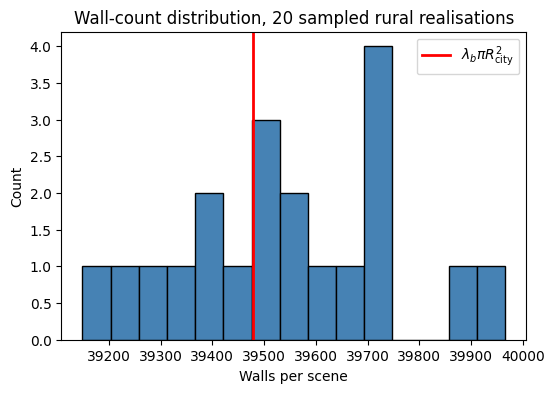

seed=0  n_walls=39557


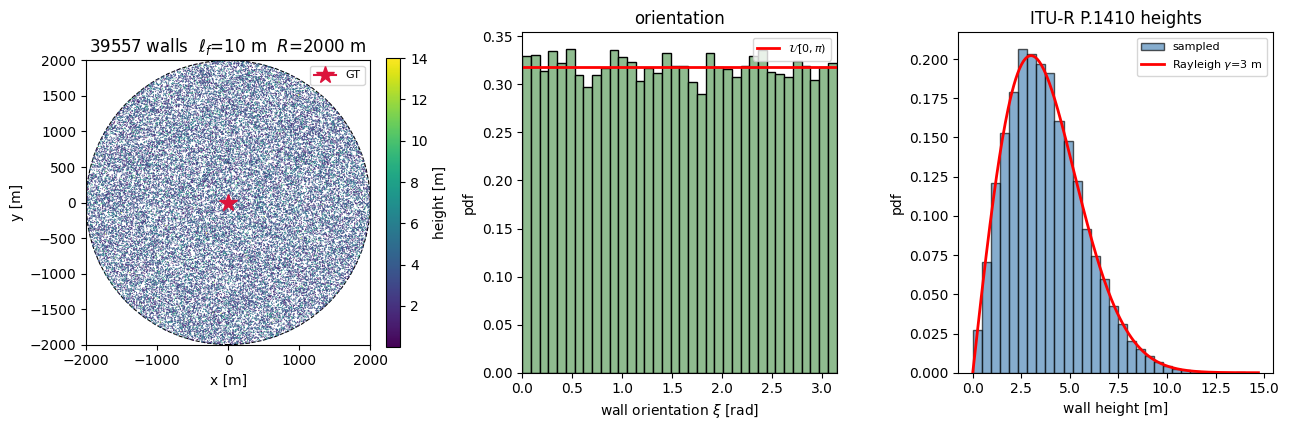

seed=1  n_walls=39485


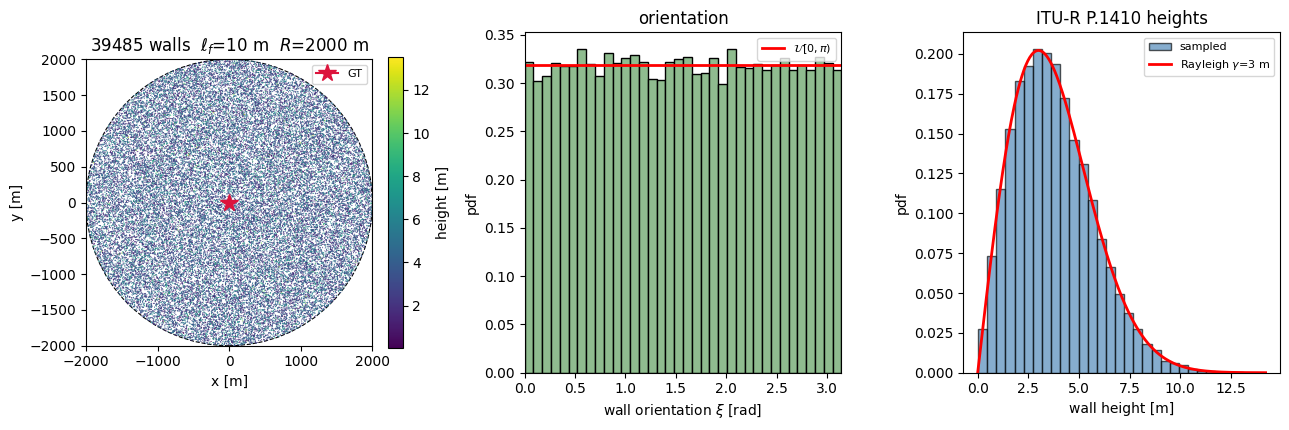

In [9]:
# Wall-count spread over the sampled scenes, then two example scenes.
# sg.plot_scene() on a wall spec shows the segments coloured by height, the
# orientation histogram against U[0, pi), and the height PDF against Rayleigh.
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(n_buildings, bins=15, color="steelblue", edgecolor="k")
ax.axvline(PPP_LAM_B * np.pi * R_CITY ** 2, color="r", lw=2,
           label=r"$\lambda_b \pi R_{\rm city}^2$")
ax.set_xlabel("Walls per scene")
ax.set_ylabel("Count")
ax.set_title(f"Wall-count distribution, {len(_specs)} sampled "
             f"{SCENARIO} realisations")
ax.legend()
fig.savefig(f"{RESULTS_ROOT}/ensemble_wall_counts_{SCENARIO}.png",
            dpi=120, bbox_inches="tight")
plt.show()

for _s in _specs[:2]:
    print(f"seed={_s.meta['seed']}  n_walls={_s.n_buildings}")
    sg.plot_scene(_s)
    plt.show()


## 6 - Launch Simulations (Multi-GPU)

Two elevation angles are dispatched simultaneously, one per GPU, by
launching `run_stochastic_sim.py` as subprocesses with different
`CUDA_VISIBLE_DEVICES` values. The same scene ensemble
(`SCENES_MANIFEST_FILE`) is passed unchanged to every elevation angle.

```
GPU 0: elev=10  ──────────────────────► done
GPU 1: elev=30  ──────────────────────► done
                                              | wait for both
GPU 0: elev=60  ──────────────────────► done
GPU 1: elev=80  ──────────────────────► done
```

Set `NUM_GPUS = 1` in Section 3 to run all angles sequentially on GPU 0.

> **Non-blocking mode:** set `BLOCK_UNTIL_DONE = False` to start the
> subprocesses and continue editing. Call `wait_for_procs(active_procs)` later.


In [10]:
# ── Launch: scene-outer sweep over scene chunks ──────────────────────────────
# One worker per GPU, each owning a contiguous block of scenes and running the
# FULL inner loop (every elevation x both polarizations) on each scene before
# discarding it. Chunks are equal-sized, so the split balances exactly -- unlike
# an elevation split, where low angles cost more than high ones.
#
# With POLARIZATION_MODE = "cp_total" this is ONE solve per elevation (RHCP
# transmit, dual-port receive, port powers summed) rather than two -- see the
# polarization block in Section 3. In "linear_copol_avg" it is two, and both run
# on the SAME loaded scene, because averaging per path needs identical geometry
# for V and H rather than two independent draws.
RESUME_CHUNKS = False   # True -> skip chunks whose result file already exists

os.makedirs(CHUNK_DIR, exist_ok=True)
print(f"{SCENARIO}: {N_SCENES} scenes over {N_WORKERS} worker(s), pol mode {POLARIZATION_MODE}")
for _start, _count in cs.chunk_bounds(N_SCENES, N_WORKERS):
    print(f"  chunk {_start:6d} .. {_start+_count-1:6d}  ({_count} scenes)")

_t0 = time.perf_counter()
cs.run_chunks(SCENARIO, SWEEP_CONFIG_FILE, CHUNK_DIR, N_SCENES,
              n_workers=N_WORKERS, resume=RESUME_CHUNKS)
print(f"\nSweep finished in {(time.perf_counter()-_t0)/3600:.2f} h")

# Merge chunks -> the ordinary results_elev{NNN}deg.pkl layout, in scene order,
# so every downstream consumer (Section 7, lsp_stats, cluster_stats) is
# unchanged. Scene order is what keeps per-scene statistics pairable across
# elevation.
cs.merge_chunks(CHUNK_DIR, RESULTS_ROOT, SCENARIO)


rural: 2000 scenes over 2 worker(s), pol mode cp_total
  chunk      0 ..    999  (1000 scenes)
  chunk   1000 ..   1999  (1000 scenes)
  $ /path/to/sionna-venv/bin/python run_chiu_sweep.py --scene-start 0 --scene-count 1000 --config ./chiu_validation/sweep_config_rural.json --output ./chiu_validation/chunks_rural_r2000 --gpu_id 0
  $ /path/to/sionna-venv/bin/python run_chiu_sweep.py --scene-start 1000 --scene-count 1000 --config ./chiu_validation/sweep_config_rural.json --output ./chiu_validation/chunks_rural_r2000 --gpu_id 1

Sweep finished in 1.02 h
[checkpoint] Results saved → ./chiu_validation/results_rural_cp/results_elev010deg.pkl
[checkpoint] Results saved → ./chiu_validation/results_rural_cp/results_elev020deg.pkl
[checkpoint] Results saved → ./chiu_validation/results_rural_cp/results_elev030deg.pkl
[checkpoint] Results saved → ./chiu_validation/results_rural_cp/results_elev040deg.pkl
[checkpoint] Results saved → ./chiu_validation/results_rural_cp/results_elev050deg.pkl
[checkp

{('cp', 10.0): 2000,
 ('cp', 20.0): 2000,
 ('cp', 30.0): 2000,
 ('cp', 40.0): 2000,
 ('cp', 50.0): 2000,
 ('cp', 60.0): 2000,
 ('cp', 70.0): 2000,
 ('cp', 80.0): 2000,
 ('cp', 90.0): 2000}

In [ ]:
# Optional manual wait + status check
# wait_for_procs(active_procs)

simulation_status(OUTPUT_DIR, ELEVATION_ANGLES)

## 7 - Channel Statistics Distributions

CDFs of the Rician K-factor (LoS receivers only) and RMS delay spread
(LoS/NLOS/all), pooled across the `N_SCENES` random PPP realisations for
each elevation angle -- each scene contributes exactly one point to these
distributions (N_RX_PER_SCENE receivers per scene), so this is the ensemble
distribution over urban-morphology randomness at the fixed
alpha/gamma/cell_res above, not spatial variation within one scene.


In [ ]:
for _pol in POLARIZATIONS:
    print(f"\n{'='*64}\n  Polarization {_pol}\n{'='*64}")
    for _angle in ELEVATION_ANGLES:
        _res = load_results(OUTPUT_DIRS[_pol], _angle)
        if _res is None:
            print(f"  elev={_angle} deg  -> no results file yet, skipping")
            continue
        plot_cdfs(_res["K_power_ratio"], _res["tau_rms_mean_s"],
                  _res["los_probability"], _angle)
        plt.show()
